# Introduction à Keras

"
Keras is a model-level library, providing high-level building blocks for developing deep learning models. It does not handle itself low-level operations such as tensor products, convolutions and so on. Instead, it relies on a specialized, well-optimized tensor manipulation library to do so, serving as the “backend engine” of Keras.*
The Python Keras API uses TensorFlow™ as it’s default tensor backend engine, however it’s possible to use other backends if desired. At this time, Keras has three backend implementations available:
-  TensorFlow is an open-source symbolic tensor manipulation framework developed by Google.
-  Theano is an open-source symbolic tensor manipulation framework developed by LISA Lab at Université de Montréal.
-  CNTK is an open-source toolkit for deep learning developed by Microsoft.
"

> Vérifier que la libraire Keras est bien installée.
> Dans le cas contraire vous pouvez installer Keras via le [gestionnaire d'environnement d'Anaconda](https://www.logicalfeed.com/posts/1224/install-tensorflow-keras-and-theano-using-anaconda-for-deep-learning), en [ligne de commandes conda](https://anaconda.org/conda-forge/keras) ou encore avec `pip install Keras`.

In [1]:
from tensorflow import keras

## Importation des données

Dans ce TP, nous allons illustrer les fonctionnalitées de [Keras](https://keras.io/getting_started/intro_to_keras_for_engineers/) sur la base de données des [handwritten digits](http://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html#sklearn.datasets.load_digits) de sckit-learn.

Il s'agit d'un problème de classification à 10 classes (10 digits).

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt

In [3]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
import tensorflow as tf  # Import TensorFlow here
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import GridSearchCV
# Install scikeras if not already installed
!pip install scikeras
from scikeras.wrappers import KerasClassifier  # Import after installing
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [4]:
digits = load_digits()

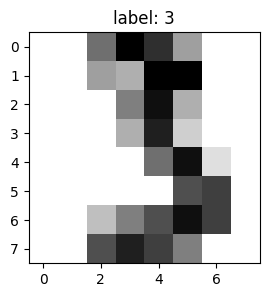

In [5]:
sample_index = 45
plt.figure(figsize=(3, 3))
plt.imshow(digits.images[sample_index], cmap=plt.cm.gray_r,
           interpolation='nearest')
plt.title("label: %d" % digits.target[sample_index]);

> Normaliser les données avec la fonction `preprocessing.scale()` et séparer celles-ci en deux échantillons d'apprentissage et de test. Afficher la dimension des deux jeux de données.

In [6]:
digits.data_nor = preprocessing.scale(digits.data)

X_train_nor, X_test_nor, y_train, y_test = train_test_split(digits.data_nor, digits.target, test_size=0.2)

Les dimensions des deux jeux de données:

In [7]:
print(X_train_nor.shape, y_train.shape)
print(X_test_nor.shape, y_test.shape)

(1437, 64) (1437,)
(360, 64) (360,)


## Feed Forward Neural Network avec Keras

Nous allons maintenant définir et ajuster un modèle à propagation avant (Feed Forward) avec Keras.

#### Pre-processing

La variable de classe (chiffre correspondant) indique le numéro de la catégorie :

In [8]:
y_train[:3]

array([9, 8, 9])

Avec Keras, pour construire un réseau de neurones adapté à ce problème de la classification multiclasses, il faut préalablement transformer la variable de classe sous la forme "one hot encoding" i.e. transformer la variable de classe en un vecteur indiquant l'appartenance à chacune des classes sous forme d'indicatrices :

In [9]:
from tensorflow.keras.utils import to_categorical

Y_train = to_categorical(y_train)
Y_train[:3]

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [0., 0., 0., 0., 0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]])

#### Definition de l'architecture

Nous allons maintenant construire un premier réseau à propagation avant :

In [10]:
from tensorflow.keras.models import Sequential

On importe les fonctionnalités qui permettent de définir, de façon successive, les différentes couches :
- Dense : permet de définir les pré-activations, c'est dans cette couche que se situent les poids et les termes de biais.
- Activation :  permet de définir les fonctions d'activation.

In [11]:
from tensorflow.keras.layers import Dense, Activation

Les dimensions du modèle :

In [12]:
N = X_train_nor.shape[1]  # dimension en entrée
N

64

In [14]:
H = 128 # dimension de la couche cachée
K = 10  # nombre de classes en sortie (autant que de chiffres ici)

On peut maintenant définir l'architecture du réseau :

In [15]:
model = Sequential()
model.add(Dense(H, input_dim=N))
model.add(Activation("relu"))
model.add(Dense(K))
model.add(Activation("softmax"))

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Il est possible de résumer l'architecture avec la méthode `summary()`:

In [16]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 10)                  │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,610 (37.54 KB)

 Trainable params: 9,610 (37.54 KB)

 Non-trainable params: 0 (0.00 B)

Le nombre de paramètres est indiqué dans la dernière colonne, notez que seules les couches `dense` contiennent ici des paramètres à ajuster.

Les dimensions en sortie de chaque couche sont de la forme `(None, ...)`. Lorsque le réseau sera ajusté sur un échantillon, la première dimension indiquera la taille de l'échantillon.

Vous pouvez visualiser (dans un fichier .png) l'architecture ainsi. Si vous êtes confronté à des problèmes d'installation (librairies `pydot`, `graphviz` ...), ne perdez pas trop de temps sur cette partie.

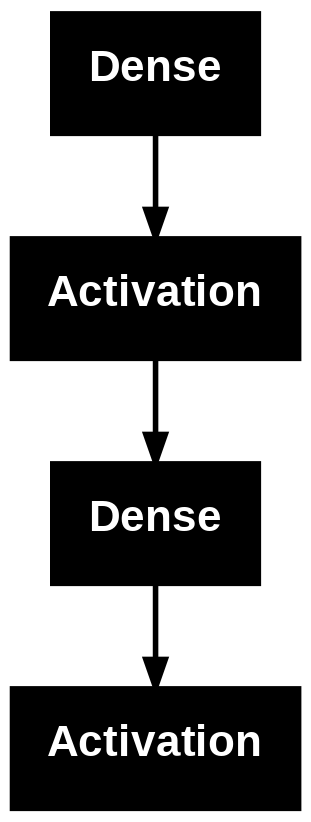

In [17]:
from tensorflow.keras.utils import plot_model
plot_model(model, to_file='model.png')

#### Poids du réseau

Le contenu (les poids) de chaque couche du réseau est accessible dans la liste `model.layers`. Par exemple pour la premiere couche :

In [19]:
my_first_layer = model.layers[0]
my_first_layer

<Dense name=dense, built=True>

Le tableau contenant les valeurs des poids et les termes de biais de cette première couche sont accessibles avec la méthode `get_weights()`. La méthode renvoie en fait une liste contenant
- le tableau numpy des poids,
- le vecteur des termes de biais.

> Vérifier que le tableau des poids ainsi que les termes de biais possèdent les dimensions attendues compte tenu de ce que nous avons vu dans le `model.summary()` plus haut. Retrouvez le nombre de paramètres affichés dans le `model.summary()`.

In [20]:
poids = my_first_layer.get_weights()[0]
biais = my_first_layer.get_weights()[1]

> Bien que le réseau n'ait pas encore été ajusté sur des données, vérifier que la définition de l'architecture implique une intialisation immédiate des poids du réseau (i.e. les poids prennent des valeurs).
> Vérifier aussi que les biais sont initialisés à zéro.

In [21]:
print("Dimensions du tableau des poids :", poids.shape)
print("Dimensions du vecteur des biais :", biais.shape)
print("Nombre de paramètres :", poids.size + biais.size)

Dimensions du tableau des poids : (64, 128)
Dimensions du vecteur des biais : (128,)
Nombre de paramètres : 8320


In [22]:
print("Poids initiaux non nuls :", np.any(poids != 0))
print("Biais initialisés à zéro :", np.all(biais == 0))

Poids initiaux non nuls : True
Biais initialisés à zéro : True


### Apprentissage : ajustement des poids du réseau

La phase d'apprentissage consiste à estimer le vecteur $\theta$ (qui contient tous les paramètres du réseau : poids et biais) en cherchant à minimiser en $\theta$ le risque empirique (ici sans pénalité)
$$ \theta \mapsto \frac 1{n} \sum_{i=1}^n  \ell( f(X_i , \theta),Y_i) $$
où $f(\cdot , \theta)$ est la fonction qui correspond au réseau de neurones et où $\ell$ est la perte choisie. Pour le problème de classification multiclasses qui nous intéresse ici il s'agit de la cross-entropy.

On utilise pour cela une méthode d'optimisation de type descente de gradient stochastique, appliquée au risque empirique pénalisé. Par exemple pour `SGD`, chaque itération effectue un pas de gradient, en calculant ce gradient sur un sous-échantillon des données (échantillon batch):
$$ \theta_b  =   \theta_{b-1}  - \varepsilon   \frac 1{|B|} \sum_{i \in B}  \nabla_\theta \ell( f(X_i , \theta_{b-1}),Y_i)   
 $$
où $\varepsilon$ est le taux d'apprentissage (learning rate).

Le module `optimizers` de Keras permet de choisir la méthode d'optimisation. On utilise ci-dessous l'optimiseur `SGD`, avec l'argument `lr` pour régler le taux d'apprentissage :

In [23]:
from tensorflow.keras.optimizers import SGD
sgd = SGD(learning_rate=0.1)

Nous allons maintenant ajuster sur les données digits un réseau de neurones à une couche cachée.

L'ajustement est effectué en deux temps : compilation puis ajustement sur les données.

On spécifie les éléments nécessaires à l'ajustement  avec la méthode  `compile` :
- optimiseur,
- perte considérée pour la back propagation (dans l'algo de descente de gradient)
- "métriques" à considérer pour évaluer l'erreur. On pourrait bien sûr évaluer l'erreur uniquement pour la cross-entropy, mais l'erreur pour la perte sèche $\ell(y,y') = 1_{y \neq y'}$ est plus facile à interpréter, on choisit donc de suivre  aussi la métrique "accuracy" (précision = taux de bien classé) le long de la trajectoire de descente de gradient.

In [ ]:
model.compile(optimizer=sgd,
              loss='categorical_crossentropy',
              metrics=['accuracy'])

Dans les arguments de la méthode `.fit` ci-dessous:
- epochs = nombre de passages sur l'ensemble de l'échantillon  ;
- batch_size = taille du sous-échantillon extrait (batch) pour le calcul du gradient à chaque itération.

In [ ]:
model.fit(X_train_nor, Y_train, epochs=10, batch_size=32)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4921 - loss: 1.6547
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9434 - loss: 0.3290
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9692 - loss: 0.1908
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9776 - loss: 0.1416
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9875 - loss: 0.0973
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9863 - loss: 0.0858
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9874 - loss: 0.0780
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9927 - loss: 0.0626
Epoch 9/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9907 - loss: 0.0593
Epoch 10/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9974 - loss: 0.0447


> Chaque ligne correspond à un passage sur l'ensemble des données (= un epoch). Nous avons choisi un batch size de 32 observations. Combien de pas de gradients sont donc effectués par epoch pour ce choix de paramètres ?

In [ ]:
# Nombre de pas de gradient par epoch
nombre_pas_gradient = X_train_nor.shape[0] // 32
print("Nombre de pas de gradients par epoch :", nombre_pas_gradient)

Nombre de pas de gradients par epoch : 44


> La perte cross entropy (ici utilisé pour désigner le risque empirique pour la cross entropy) et la précision (accuracy) s'améliorent-elles le long de la trajectoire de descente de gradient ?

Les poids sont enregistrés dans `model.layers`.

> Les biais sont ils toujours à zero ?

In [ ]:
print("Biais après l'apprentissage :")
for layer in model.layers:
    if layer.get_weights():
        print(np.all(layer.get_weights()[0] == 0))

Biais après l'apprentissage :
False
False


> En comparant les valeurs de la perte et de l'accuracy, vérifier (sur les sorties) que si l'on effectue l'ajustement une seconde fois, l'état initial pour le second essai correspond à l'état du réseau précédemment ajusté.

> Essayer de diminuer encore la perte en augmentant le nombre d'épochs, en diminuant le taux d'apprentissage (par exemple 0.001).   
> Remarque : si vous souhaitez réinitialiser les poids, il vous faut "réinstancier" le modèle en le redéfinissant totalement.

In [ ]:
model = Sequential()
model.add(Dense(H, input_dim=N))
model.add(Activation("relu"))
model.add(Dense(K))
model.add(Activation("softmax"))
sgd = SGD(learning_rate=0.001)
model.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(X_train_nor, Y_train, epochs=100, batch_size=32)

Epoch 1/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1880 - loss: 2.2901
Epoch 2/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.2264 - loss: 2.2338
Epoch 3/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2632 - loss: 2.1247
Epoch 4/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.2924 - loss: 2.0893
Epoch 5/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3523 - loss: 1.9683
Epoch 6/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3912 - loss: 1.9112
Epoch 7/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4295 - loss: 1.8673
Epoch 8/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4599 - loss: 1.8020
Epoch 9/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4982 - loss: 1.7348
Epoch 10/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5080 - loss: 1.7048
Epoch 11/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5511 - loss: 1.6313
Epoch 12/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy:

> Que dire de la convergence pour une grande valeur du taux d'apprentissage (par exemple `lr=2`) ?

In [ ]:
sgd = SGD(learning_rate=2.0)
model.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(X_train_nor, Y_train, epochs=10, batch_size=32)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5489 - loss: 123.4896
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7455 - loss: 1359.1240
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4827 - loss: 641792.8125
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6298 - loss: 165703952.0000
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5422 - loss: 102222708736.0000
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7262 - loss: 1242249822208.0000
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5330 - loss: 512575389302784.0000
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5936 - loss: 27031345192501248.0000
Epoch 9/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5820 - loss: 16987615177836855296.0000
Epoch 10/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7048 - loss: 1672858844624538566656.0000


> Essayer aussi d'utiliser une méthode `Momentum-SGD` (argument `momentum= True`).  

In [ ]:
sgd = SGD(learning_rate=0.1, momentum=0.9)
model.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(X_train_nor, Y_train, epochs=10, batch_size=32)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7465 - loss: 32973962607522100543488.0000
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9300 - loss: 3139375139221936275456.0000
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9750 - loss: 1370518409365298348032.0000
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9839 - loss: 690008672702176428032.0000
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9761 - loss: 361417247796202831872.0000
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9913 - loss: 578642746322884493312.0000
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9810 - loss: 743644573939322060800.0000
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9911 - loss: 348034238553517981696.0000
Epoch 9/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9941 - loss: 16213090599929118720.0000
Epoch 10/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy

In [ ]:
sgd = SGD(learning_rate=0.1, momentum=0.9)
model.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(X_train_nor, Y_train, epochs=10, batch_size=32)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9983 - loss: 7653406321588305920.0000
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9992 - loss: 5588119963857584128.0000
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9984 - loss: 16167989732469374976.0000
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9994 - loss: 2559992922950860800.0000
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9988 - loss: 10480212783449243648.0000
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0000e+00
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0000e+00
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0000e+00
Epoch 9/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.0000e+00
Epoch 10/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0000e+00


### Predictions et erreur de généralisation

> Effectuer des prédictions de votre réseau sur l'échantillon test avec la méthode `.predict()`.

In [ ]:
import numpy as np
y_predicted_probs = model.predict(X_test_nor)
y_predicted = np.argmax(y_predicted_probs, axis=1)

print(y_predicted)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
[7 6 7 4 5 5 6 1 5 9 5 1 3 8 9 4 5 2 5 8 1 0 7 0 6 9 0 1 2 6 4 9 2 5 7 2 0
 0 9 0 6 6 2 6 5 4 0 1 8 5 8 7 8 3 9 7 0 3 6 7 3 7 1 0 6 9 0 4 7 7 6 4 8 9
 8 4 2 5 5 4 5 2 2 5 3 2 8 8 3 8 1 9 2 5 9 6 6 8 2 2 6 0 1 4 5 7 9 1 3 9 8
 2 1 4 1 3 1 5 8 1 0 2 2 4 8 7 7 2 8 5 7 8 9 3 3 9 9 1 3 5 1 8 2 4 4 7 7 8
 5 4 2 3 8 4 3 3 0 5 0 6 8 5 3 1 0 2 9 4 6 5 7 7 0 4 5 4 9 5 9 3 7 1 0 9 5
 8 8 6 8 1 4 3 9 6 5 1 3 4 7 5 1 2 4 2 7 5 4 1 5 4 0 7 4 5 8 9 7 9 4 6 2 4
 7 8 0 6 5 6 0 6 7 1 2 6 6 9 0 3 0 0 1 3 9 9 8 2 8 8 3 2 5 8 6 9 0 8 8 7 2
 4 1 4 2 7 7 4 8 0 9 3 0 6 2 8 6 9 9 3 2 0 2 5 2 9 7 1 2 3 5 5 3 0 8 8 6 8
 8 5 0 6 6 1 8 2 4 0 9 2 5 4 0 1 9 3 8 6 7 9 4 5 4 3 1 6 9 9 7 1 1 1 4 3 9
 0 5 1 7 1 0 9 2 7 6 6 3 0 0 0 1 7 5 0 9 3 6 6 0 5 8 0]


> Pour plusieurs élements de l'échantillon test, renvoyer les probabilités conditionnelles prédites par le réseau (en sortie du Softmax) à l'aide de la méthode `.model.predict()`. La probabilité de la classe choisie est-elle générallement bien supérieure aux probabilités des autres classes ?
Calculer le taux de bien classé sur l'échantillon test.

Text(0.5, 1.0, 'predicted label: 7\n true label: 7')

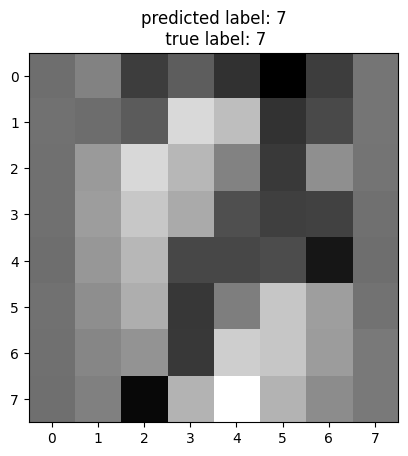

In [ ]:
sample_idx = 2
plt.imshow(X_test_nor[sample_idx].reshape(8, 8),
           cmap=plt.cm.gray_r, interpolation='nearest');
plt.title("predicted label: %d\n true label: %d"
              % (y_predicted[sample_idx], y_test[sample_idx]))

In [ ]:
probabilities = probabilities = model.predict(X_test_nor)
print(probabilities[sample_idx])

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
[0.         0.         0.         0.         0.         0.
 0.         0.99999994 0.         0.        ]


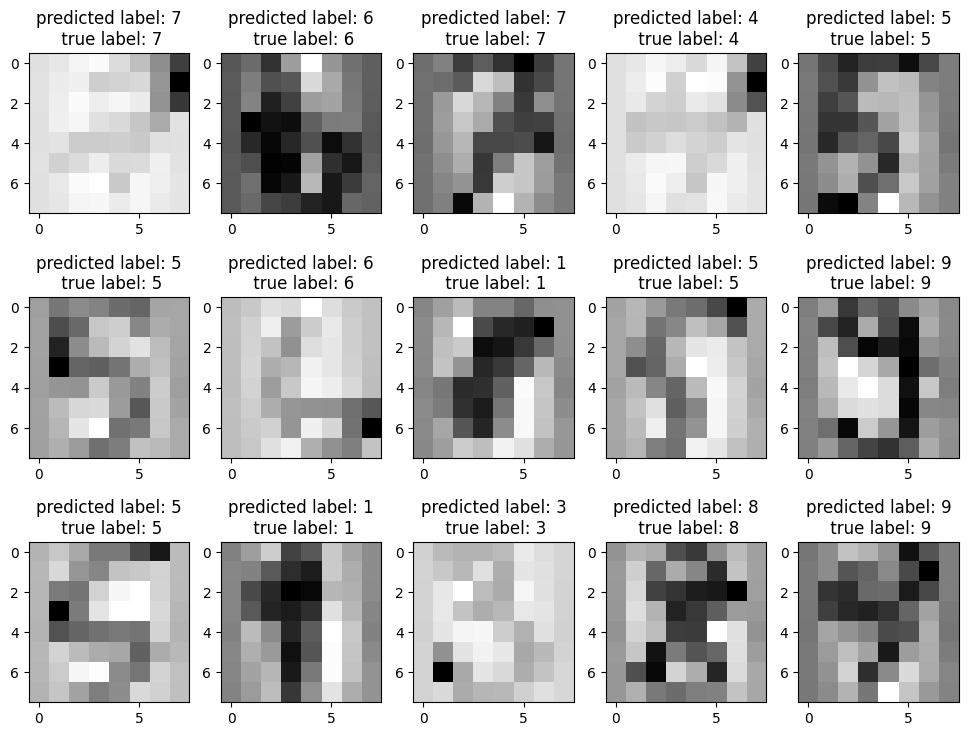

In [ ]:
plt.figure(figsize=(12, 9))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test_nor[i].reshape(8, 8),
               cmap=plt.cm.gray_r, interpolation='nearest')
    plt.title("predicted label: %d\n true label: %d"
              % (y_predicted[i], y_test[i]))


In [ ]:
erreur_empirique = - np.mean(np.log(probabilities[np.arange(len(y_test)), y_test]))
print("Risque empirique sur l'échantillon test :", erreur_empirique)

Risque empirique sur l'échantillon test : inf


<ipython-input-95-ce384fb9566a>:1: RuntimeWarning: divide by zero encountered in log
  erreur_empirique = - np.mean(np.log(probabilities[np.arange(len(y_test)), y_test]))


On rappelle que la perte empirique pour la cross-entropy vaut
\begin{eqnarray*}
\hat{ \mathcal R}_n (\theta)  &=&  \frac 1n  \sum_{i=1}^n  \ell( Y_i,  f(X_i , \theta)) \\
& =&   -    \frac 1n \sum_{i=1}^n  \sum_{k = 1}^K  \mathbb{1}_{Y_i =  k}  \log (f(X_i , \theta)_k)  
\end{eqnarray*}


> Calculer ("à la main") le risque empirique (pour la cross entropy) sur l'échantillon test. Le risque était-il plus faible sur l'échantillon d'apprentissage  ?

In [ ]:
n_test = len(y_test)  # Number of samples in the test set
cross_entropy_loss = -np.log(probabilities[np.arange(n_test), y_test])
empirical_risk_test = np.mean(cross_entropy_loss)

print("Empirical Risk (Cross-entropy) on Test Set:", empirical_risk_test)

Empirical Risk (Cross-entropy) on Test Set: inf


<ipython-input-96-b70753985777>:2: RuntimeWarning: divide by zero encountered in log
  cross_entropy_loss = -np.log(probabilities[np.arange(n_test), y_test])


> Plus simplement, on peut utiliser la méthode `.evaluate(x,y)`  pour retrouver la perte empirique et l'accuracy. Ce calcul correspond-il à une passe de propagation avant ou bien à un pas de back-propagation ?

In [ ]:
score = model.evaluate(X_test_nor, to_categorical(y_test), verbose=0)
print('Perte empirique sur l\'échantillon test:', score)
print('Accuracy sur l\'échantillon test:', score)

Perte empirique sur l'échantillon test: [2.6903023615533845e+21, 0.9583333134651184]
Accuracy sur l'échantillon test: [2.6903023615533845e+21, 0.9583333134651184]


### Impact de l'initialisation

Nous allons maintenant étudier l'impact de l'initialisation de la méthode SGD sur la convergence de ce dernier.

Dans Keras, par défaut les poids sont initialisés comme suit par l'initialiseur `glorot_uniform` :

- chaque poids est tiré uniformément dans $[-scale, scale]$
- scale est choisi de l'ordre de $\frac{1}{\sqrt{n_{in} + n_{out}}}$

Nous allons étudier l'impact de l'initialisation en considérant des initialiseurs Gaussiens en testant plusieurs valeurs pour la variance.

In [ ]:
from tensorflow.keras import initializers
mon_init1 = initializers.RandomNormal(mean=0.0, stddev=0.05)

> Définir un réseau avec une couche Softmax en sortie et deux couches cachées "tanh", avec respectivement H neurones et K neurones. (On utilise ici des activations "tanh" pour que le problème soit un peu plus difficile à résoudre pour le réseau ...)
> Passer l'initialiseur en argument de `Dense()`, ce qui donne par exemple pour la première couche :   
`model.add(Dense(H,input_dim=N,kernel_initializer=mon_init1))`.

In [ ]:
model = Sequential()
model.add(Dense(H, input_dim=N, kernel_initializer=mon_init1, activation='tanh'))
model.add(Dense(K, kernel_initializer=mon_init1, activation='tanh'))
model.add(Dense(K, kernel_initializer=mon_init1, activation='softmax'))

sgd = SGD(learning_rate=0.1)
model.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['accuracy'])


> Ajuster le réseau et afficher l'évolution de la perte (i.e. risque empirique) sur les données d'apprentissage le long de la trajectoire des epochs.

In [ ]:
history1 = model.fit(X_train_nor, Y_train, epochs=100, batch_size=32, verbose=0)

On peut afficher l'évolution de la perte sur l'apprentissage comme suit :

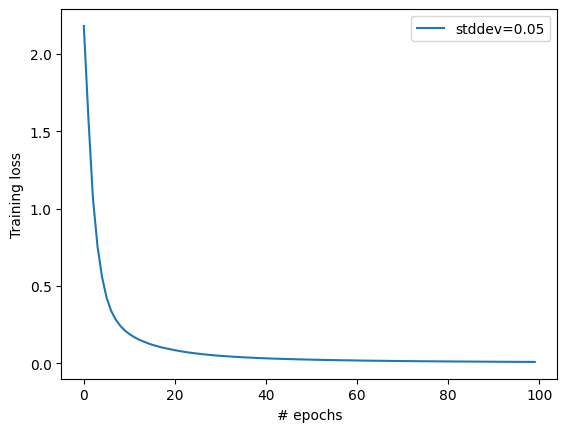

In [ ]:
plt.plot(history1.history['loss'],label = "stddev=0.05")
plt.xlabel('# epochs')
plt.ylabel('Training loss')
#plt.ylim(0, 6)
plt.legend(loc='best');

> Faire de même avec les initialiseurs suivants :    
> `mon_init2 = initializers.RandomNormal(mean=0.0,stddev=10)`   
> `mon_init3 = initializers.RandomNormal(mean=0.0,stddev=0.001)` \
> `mon_init4 = initializers.glorot_uniform()`    

In [ ]:
mon_init2 = initializers.RandomNormal(mean=0.0, stddev=10)
mon_init3 = initializers.RandomNormal(mean=0.0, stddev=0.001)
mon_init4 = initializers.glorot_uniform()

> Comparer les performance des réseaux ajustés avec ces initialiseurs en représentant les "trajectoires d'apprentissage".

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1032 - loss: 53.9627
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.0962 - loss: 51.2528
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1146 - loss: 44.8077
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1055 - loss: 43.1147
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1236 - loss: 38.5462
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.1688 - loss: 33.8808
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.1605 - loss: 32.0052
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1917 - loss: 30.6875
Epoch 9/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1846 - loss: 28.2792
Epoch 10/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1941 - loss: 26.1228
Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.1105 - loss: 2.3030
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2

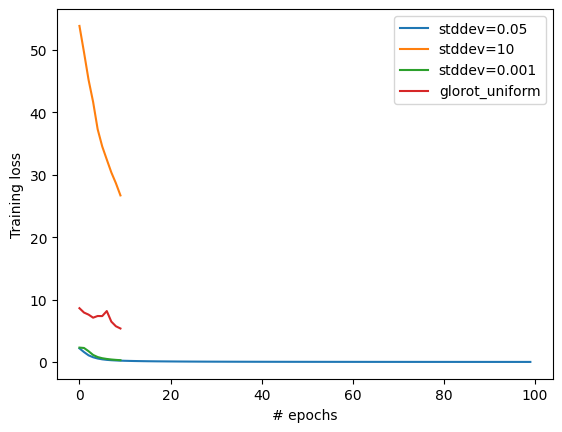

In [ ]:
sgd = SGD(learning_rate=0.1)
model2 = Sequential()
model2.add(Dense(H, input_dim=N, kernel_initializer=mon_init2,activation="tanh"))
model2.add(Dense(K, kernel_initializer=mon_init2,activation="tanh"))
model2.add(Dense(K, kernel_initializer=mon_init2,activation="softmax"))
model2.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['accuracy'])
history2 = model2.fit(X_train_nor, Y_train, epochs=10, batch_size=32)
sgd = SGD(learning_rate=0.1)
model3 = Sequential()
model2.add(Dense(H, input_dim=N, kernel_initializer=mon_init3,activation="tanh"))
model3.add(Dense(K, kernel_initializer=mon_init3,activation="tanh"))
model3.add(Dense(K, kernel_initializer=mon_init3,activation="softmax"))
model3.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['accuracy'])
history3 = model3.fit(X_train_nor, Y_train, epochs=10, batch_size=32)
sgd = SGD(learning_rate=0.1)
model4 = Sequential()
model4.add(Dense(H, input_dim=N, kernel_initializer=mon_init4,activation="tanh"))
model4.add(Dense(K, kernel_initializer=mon_init4,activation="tanh"))
model2.add(Dense(K, kernel_initializer=mon_init4,activation="softmax"))
model4.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['accuracy'])
history4 = model4.fit(X_train_nor, Y_train, epochs=10, batch_size=32)

plt.plot(history1.history['loss'], label="stddev=0.05")
plt.plot(history2.history['loss'], label="stddev=10")
plt.plot(history3.history['loss'], label="stddev=0.001")
plt.plot(history4.history['loss'], label="glorot_uniform")
plt.xlabel('# epochs')
plt.ylabel('Training loss')
plt.legend(loc='best')
plt.show()

Conclusion:
- Initialisation trop proche de zero : gradients trop faibles et SGD peine à sortir de cette zone ...
- Initialisation avec des amplitudes trop élevées : les couches intermédiaires ont des gradients qui s'annulent et difficile là encore de sortir de cette zone

### Early Stopping


L'argument ` validation_split=0.1` dans la méthode `.fit()` permet d'évaluer la perte sur un échantillon de validation.

> Vérifier graphiquement qu'après un certain nombre d'itérations (quelques centaines epochs ici), le risque et la précision sur l'échantillon de validation  finissent par se dégrader.

Epoch 1/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5431 - loss: 1.6267 - val_accuracy: 0.8472 - val_loss: 0.8853
Epoch 2/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9038 - loss: 0.7636 - val_accuracy: 0.9028 - val_loss: 0.5847
Epoch 3/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9508 - loss: 0.5209 - val_accuracy: 0.9306 - val_loss: 0.4350
Epoch 4/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9532 - loss: 0.3856 - val_accuracy: 0.9514 - val_loss: 0.3549
Epoch 5/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9629 - loss: 0.3106 - val_accuracy: 0.9583 - val_loss: 0.2875
Epoch 6/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9669 - loss: 0.2622 - val_accuracy: 0.9514 - val_loss: 0.2486
Epoch 7/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9684 - loss: 0.2178 - val_accuracy: 0.9514 - val_loss: 0.2313
Epoch 8/200
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9822 - loss: 0.1702 - val_accuracy: 0.9514 - v

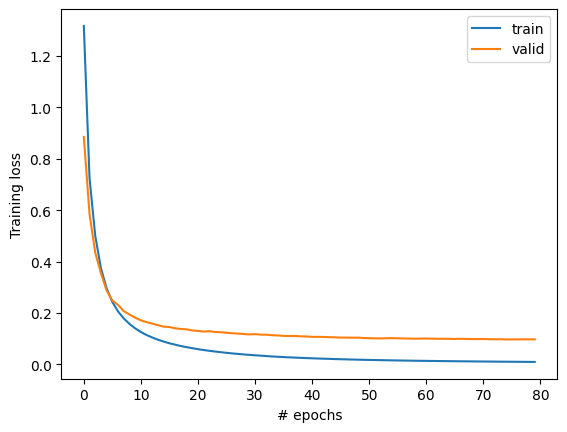

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor='val_loss', patience=5)

model = Sequential()
model.add(Dense(H, input_dim=N, kernel_initializer=mon_init4))
model.add(Activation("tanh"))
model.add(Dense(K, kernel_initializer=mon_init4))
model.add(Activation("tanh"))
model.add(Dense(K, kernel_initializer=mon_init4))
model.add(Activation("softmax"))
# Change 'lr' to 'learning_rate'
sgd = SGD(learning_rate=0.1)
model.compile(optimizer=sgd, loss='categorical_crossentropy', metrics=['accuracy'])
history = model.fit(X_train_nor, Y_train, epochs=200, batch_size=32, validation_split=0.1, callbacks=[early_stopping])

plt.plot(history.history['loss'], label="train")
plt.plot(history.history['val_loss'], label="valid")
plt.xlabel('# epochs')
plt.ylabel('Training loss')
plt.legend(loc='best')
plt.show()

Les réseaux de neurones, même sans parler des architectures "profondes", nécessitent d'ajuster un très grand nombre de paramètres. Il est donc naturel de devoir contrôler la complexité statistique de ces prédicteurs pour en obtenir les meilleurs erreurs de généralisation.

A chaque pas de la descente de gradient l'ensemble des poids et des biais du réseau est mis à jour. A chaque pas de la descente correspond donc un prédicteur, et au final on dispose donc d'une suite de prédicteurs. Le prédicteur final (du dernier pas de gradient) est certes celui qui minimise le risque empirique (appelée ici perte) mais cela ne signifie évidemment pas que ce prédicteur a les meilleurs performances sur l'échantillon de validation (ou de test).

Typiquement, le long de la descente de gradient, le biais du prédicteur construit tend à diminuer alors que la variance tend à augmenter. Il s'agit donc de choisir le nombre de pas de gradients pour réaliser un compromis optimal entre biais et variance. Noter que le nombre de pas de gradients joue ici le rôle de mesure de la complexité statistique.


La méthode classiquement utilisée pour choisir le nombre de pas de gradients est celle du "early stopping".  Le principe consiste tout simplement à stopper la descente de gradient stochastique lorsque l'erreur de validation remonte. L'argument `monitor='val_loss'` de la fonction `EarlyStopping` indique que c'est l'erreur de validation calculée pour la perte (ici cross entropy) qui sera surveillée.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5)

Le long d'une trajectoire de descente de gradient, il est possible que la perte remonte ponctuellement sur une itération, avant de redescendre aussitôt. Il est donc préférable de ne prendre la décision d'arrêter la descente de gradient que si cette remontée se confirme sur quelques itérations successives. L'argument `patience=5` impose à la descente de gradient de patienter 5 itérations après une remontée de la perte, avant de prendre la décision d'arrêter  ou non l'algorithme.

In [ ]:
model = Sequential()

model.add(Dense(H,input_dim=N, kernel_initializer=mon_init4))
model.add(Activation("tanh"))
model.add(Dense(K,kernel_initializer=mon_init4))
model.add(Activation("tanh"))
model.add(Dense(K,kernel_initializer=mon_init4))
model.add(Activation("softmax"))
sgd = SGD(learning_rate=0.1)

model.compile(optimizer=sgd,
              loss='categorical_crossentropy',
              metrics = ['accuracy'] )

history = model.fit(X_train_nor, Y_train,epochs=500,
          batch_size=32,verbose=0,
          validation_split=0.1,
          callbacks=[early_stopping])

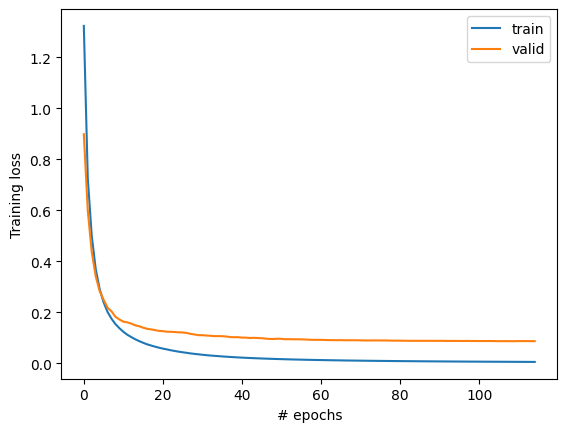

In [ ]:
plt.plot(history.history['loss'],label ="train")
plt.plot(history.history['val_loss'],label ="valid")
plt.xlabel('# epochs')
plt.ylabel('Training loss')
plt.legend(loc='best');

> Donner la prédiction du dernier modèle ajusté (par early stopping) sur l'échantillon test `X_test_nor`. Calculer le risque estimé sur les données de test en utilisant la méthode `.evaluate()`. Calculer enfin le taux de mauvais classement sur l'échantillon test.

In [ ]:
import numpy as np

# Obtenir les prédictions sur l'échantillon de test
y_predicted_probs = model.predict(X_test_nor)  # Obtenez les probabilités prédites

# Obtenir les classes prédites en utilisant argmax
y_predicted = np.argmax(y_predicted_probs, axis=1)

# Calculer la perte et l'accuracy sur l'échantillon de test
perte, accuracy = model.evaluate(X_test_nor, to_categorical(y_test), verbose=0)

# Calculer le taux de mauvais classement
taux_mauvais_classement = 1 - accuracy

# Afficher les résultats
print("Prédictions sur l'échantillon de test :", y_predicted)
print("Risque estimé sur les données de test :", perte)
print("Taux de mauvais classement sur l'échantillon de test :", taux_mauvais_classement)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Prédictions sur l'échantillon de test : [7 6 7 4 5 5 6 1 5 9 5 1 3 8 9 4 5 2 5 8 1 0 7 0 6 9 0 1 2 6 4 9 2 5 7 3 0
 0 9 0 6 6 2 6 5 4 0 1 1 5 8 7 1 7 9 7 0 3 6 7 3 7 1 0 6 9 0 4 7 7 6 4 8 9
 8 4 2 5 5 4 5 2 1 5 3 2 8 8 3 8 1 9 2 5 9 6 6 8 2 2 6 0 1 4 5 7 9 1 3 9 8
 2 1 4 1 3 1 5 8 1 0 2 2 4 8 7 7 2 8 5 7 8 9 3 3 9 9 1 3 5 1 4 2 4 4 7 7 8
 5 4 2 3 8 4 3 3 0 5 0 6 8 5 3 1 0 2 9 4 6 5 7 7 0 4 4 4 9 5 5 3 7 1 0 9 5
 8 8 6 3 1 4 3 9 6 5 1 3 4 7 5 1 2 4 2 7 5 4 1 5 4 0 7 4 5 8 9 7 9 4 6 2 4
 7 8 4 6 5 6 0 6 7 1 2 6 6 9 0 3 0 0 1 3 9 9 8 2 8 8 3 2 5 9 6 9 0 8 8 7 2
 4 1 4 2 7 7 4 8 0 9 3 0 6 2 8 6 5 9 2 2 0 2 5 2 8 7 1 2 3 5 5 3 0 8 8 6 8
 8 5 0 6 6 1 8 2 4 0 9 2 5 4 0 1 9 3 8 6 7 9 4 9 4 3 1 6 3 9 7 1 1 1 4 3 9
 0 5 1 7 1 0 9 2 7 6 6 3 0 0 0 1 7 5 0 9 3 6 6 0 5 8 0]
Risque estimé sur les données de test : 0.16115780174732208
Taux de mauvais classement sur l'échantillon de test : 0.03333336114883423


## Application : Données MNIST

Charger les données [handwritten digits MNIST](http://yann.lecun.com/exdb/mnist/) :

In [ ]:
from tensorflow.keras.datasets import mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

height, width, depth = 28, 28, 1 #  28x28 and 1 canal pour le niveau de gris
num_classes = 10

num_train = 60000
num_test = 10000

X_train = X_train.reshape(num_train, height * width)  # vecteur
X_test = X_test.reshape(num_test, height * width) # vecteur

X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

X_train_nor = X_train / 255 # normalisation dans  [0, 1]

X_test_nor = X_test / 255 # normalisation dans  [0, 1]

> Définir et ajuster un réseau de neurones à deux couches cachées.
> On pourra dans un premier temps choisir les paramètres ci-dessous.
> On pourra aussi utiliser l'optimiseur adagrad :    
> `adag = tensorflow.keras.optimizers.Adagrad(lr=0.01)`

In [ ]:
batch_size = 128
num_epochs = 40
hidden_size = 512

In [ ]:
# Définir les paramètres du modèle
adag = tf.keras.optimizers.Adagrad(learning_rate=0.01)
model = Sequential()
model.add(Dense(hidden_size, input_dim=height * width, activation='relu'))
model.add(Dense(hidden_size, activation='relu'))
model.add(Dense(num_classes, activation='softmax'))
model.compile(optimizer=adag, loss='categorical_crossentropy', metrics=['accuracy'])
# Ajuster le modèle aux données d'apprentissage
model.fit(X_train_nor, to_categorical(y_train), epochs=num_epochs, batch_size=batch_size)

Epoch 1/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.7190 - loss: 1.1060
Epoch 2/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9108 - loss: 0.3168
Epoch 3/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9289 - loss: 0.2477
Epoch 4/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.9369 - loss: 0.2187
Epoch 5/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9449 - loss: 0.1961
Epoch 6/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9509 - loss: 0.1712
Epoch 7/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9565 - loss: 0.1553
Epoch 8/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9595 - loss: 0.1418
Epoch 9/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - accuracy: 0.9627 - loss: 0.1327
Epoch 10/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9661 - loss: 0.1230
Epoch 11/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9673 - loss: 0.1166
Epoch 12/40
469/469 ━━━━━━━━━━━━━━━━━

> En reproduisant les codes proposés sur ce [blog](https://machinelearningmastery.com/use-keras-deep-learning-models-scikit-learn-python/), essayer d'améliorer les performances de votre réseau en choisissant mieux les paramètres par validation croisée à l'aide de la fonction `GridSearchCV` de sckit-learn. Attention, cette validation croisée s'avère très couteuse en temps de calcul...

In [ ]:
# Définir une fonction qui crée le modèle Keras
def creer_modele(hidden_size=512, activation='relu'):
    model = Sequential()
    model.add(Dense(hidden_size, input_dim=height * width, activation=activation))
    model.add(Dense(hidden_size, activation=activation))
    model.add(Dense(num_classes, activation='softmax'))
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model
# Créer un classificateur Keras enveloppé pour scikit-learn,
# passing model-building function and its parameters
model = KerasClassifier(model=creer_modele, verbose=0, hidden_size=512, activation='relu')

# Définir les paramètres à rechercher. Note 'activation' is removed
param_grid = {
    #'learning_rate:' : [0.001, 0.01, 0.1],
    'hidden_size': [128, 256, 512],
    'batch_size': [16, 32, 64],
    'epochs': [1, 2, 3]
}

grid = GridSearchCV(estimator=model, param_grid=param_grid, cv=3)

grid_result = grid.fit(X_train_nor, to_categorical(y_train))

print("Meilleurs paramètres :", grid_result.best_params_)

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/lo

KeyboardInterrupt: 